# Avaliação de Modelos - Overcooked
# Análise Comparativa de Modelos Treinados

#### Thaís Ferreira da Silva - 2021092571

**Objetivo:** Carregar e avaliar os modelos salvos durante o treinamento, comparando performance e visualizando comportamentos.

---

## 1. Setup e Imports

In [112]:
# Bibliotecas padrão
import os
import sys
import time
import random
from pathlib import Path
from typing import Dict, List, Tuple
import json

# Bibliotecas científicas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pandas as pd

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical

# Ambiente
import gymnasium as gym
from overcooked_marl_env import OvercookedMARL

# Configurações
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")

# Device detection
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Device: {device}")

Device: cuda


## 2. Definição das Classes

In [113]:
class PettingZooToGymWrapper(gym.Env):
    def __init__(self, pettingzoo_env):
        super().__init__()
        self.env = pettingzoo_env
        
        if len(self.env.possible_agents) != 1:
            raise ValueError(f"Wrapper funciona apenas com 1 agente. Encontrados: {len(self.env.possible_agents)}")
        
        self.agent_id = self.env.possible_agents[0]
        self.action_space = self.env.action_spaces[self.agent_id]
        self.observation_space = self.env.observation_spaces[self.agent_id]
        
    def reset(self, seed=None, options=None):
        observations, infos = self.env.reset(seed=seed, options=options)
        return observations[self.agent_id], infos[self.agent_id]
    
    def step(self, action):
        actions = {self.agent_id: action}
        observations, rewards, terminations, truncations, infos = self.env.step(actions)
        
        obs = observations[self.agent_id]
        reward = rewards[self.agent_id]
        terminated = terminations[self.agent_id]
        truncated = truncations[self.agent_id]
        info = infos[self.agent_id]
        
        return obs, reward, terminated, truncated, info
    
    def render(self):
        return self.env.render()
    
    def close(self):
        self.env.close()

class ActorCritic(nn.Module):
    def __init__(self, observation_space, action_space):
        super().__init__()
        
        h, w, c = observation_space.shape
        n_actions = action_space.n
        
        # Feature extractor (CNN)
        self.cnn = nn.Sequential(
            nn.Conv2d(c, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Flatten(),
        )
        
        # Calcula tamanho da saída
        with torch.no_grad():
            sample = torch.zeros(1, c, h, w)
            n_flatten = self.cnn(sample).shape[1]
        
        # Camadas compartilhadas
        self.shared = nn.Sequential(
            nn.Linear(n_flatten, 128),
            nn.ReLU(),
        )
        
        # Heads
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)
    
    def forward(self, x):
        x = x.permute(0, 3, 1, 2)
        features = self.shared(self.cnn(x))
        logits = self.actor(features)
        value = self.critic(features)
        return logits, value
    
    def get_action_and_value(self, x, action=None):
        logits, value = self.forward(x)
        probs = Categorical(logits=logits)
        
        if action is None:
            action = probs.sample()
        
        return action, probs.log_prob(action), probs.entropy(), value

## 3. Carregamento e Análise dos Modelos Salvos

In [114]:
def load_model_info(model_path: Path) -> Dict:
    try:
        # CORREÇÃO: Usar weights_only=False para carregar metadados dos modelos
        checkpoint = torch.load(model_path, map_location='cpu', weights_only=False)
        
        # Extrai informações da nova estrutura de checkpoint
        config = checkpoint.get('config', {})
        reward = checkpoint.get('reward', 0.0)
        episode_rewards = checkpoint.get('episode_rewards', [])
        episode_lengths = checkpoint.get('episode_lengths', [])
        
        # Retorna estrutura compatível
        return {
            'reward': reward,
            'config': config,
            'total_episodes': len(episode_rewards),
            'mean_reward': np.mean(episode_rewards) if episode_rewards else 0.0,
            'std_reward': np.std(episode_rewards) if episode_rewards else 0.0,
            'episode_rewards': episode_rewards,
            'episode_lengths': episode_lengths
        }
    except Exception as e:
        print(f"Erro ao carregar {model_path}: {e}")
        return {}

def discover_saved_models(models_dir: str = "models") -> List[Dict]:
    models_path = Path(models_dir)
    
    if not models_path.exists():
        return []
    
    models_info = []
    
    # Carrega modelos config_*.pth
    for model_file in models_path.glob("config_*.pth"):
        info = load_model_info(model_file)
        if info:
            info['path'] = str(model_file)
            info['type'] = 'config'
            info['filename'] = model_file.name
            models_info.append(info)
    
    return models_info

# Descobrir modelos
models_info = discover_saved_models()

if models_info:
    # Cria DataFrame para análise
    df_models = pd.DataFrame(models_info)
    
    # Ordena por reward (decrescente)
    df_models = df_models.sort_values('reward', ascending=False).reset_index(drop=True)
    
    print(f"Modelos encontrados: {len(models_info)}")
    print("\nResumo dos modelos:")
    for i, row in df_models.iterrows():
        print(f"{i+1:2d}. {row['filename']:30} | Reward: {row['reward']:7.2f} | Episodes: {row['total_episodes']:3d}")
else:
    print("Nenhum modelo encontrado. Execute primeiro o treinamento no notebook 'TP_Overcooked.ipynb'.")
    print("Diretórios verificados:")
    print("- models/config_*.pth")

Modelos encontrados: 27

Resumo dos modelos:
 1. config_03_reward_159.05.pth    | Reward:  159.05 | Episodes:  19
 2. config_11_reward_152.95.pth    | Reward:  152.95 | Episodes:  19
 3. config_15_reward_151.89.pth    | Reward:  151.89 | Episodes:  19
 4. config_07_reward_132.63.pth    | Reward:  132.63 | Episodes:  19
 5. config_09_reward_131.47.pth    | Reward:  131.47 | Episodes:  19
 6. config_19_reward_124.11.pth    | Reward:  124.11 | Episodes:  19
 7. config_12_reward_119.79.pth    | Reward:  119.79 | Episodes:  19
 8. config_01_reward_119.40.pth    | Reward:  119.40 | Episodes:  10
 9. config_18_reward_118.95.pth    | Reward:  118.95 | Episodes:  19
10. config_08_reward_118.63.pth    | Reward:  118.63 | Episodes:  19
11. config_04_reward_117.58.pth    | Reward:  117.58 | Episodes:  19
12. config_14_reward_115.68.pth    | Reward:  115.68 | Episodes:  19
13. config_02_reward_112.80.pth    | Reward:  112.80 | Episodes:  10
14. config_10_reward_110.74.pth    | Reward:  110.74 | Epi

## 4. Análise Comparativa de Performance

4.1 - CURVAS DE APRENDIZADO (Top 5 Modelos)


c:\Users\thais\Github\NewOvercookedEnv\venv\Lib\site-packages\numpy\_core\_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\thais\Github\NewOvercookedEnv\venv\Lib\site-packages\numpy\_core\_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\thais\Github\NewOvercookedEnv\venv\Lib\site-packages\numpy\_core\_methods.py:214: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


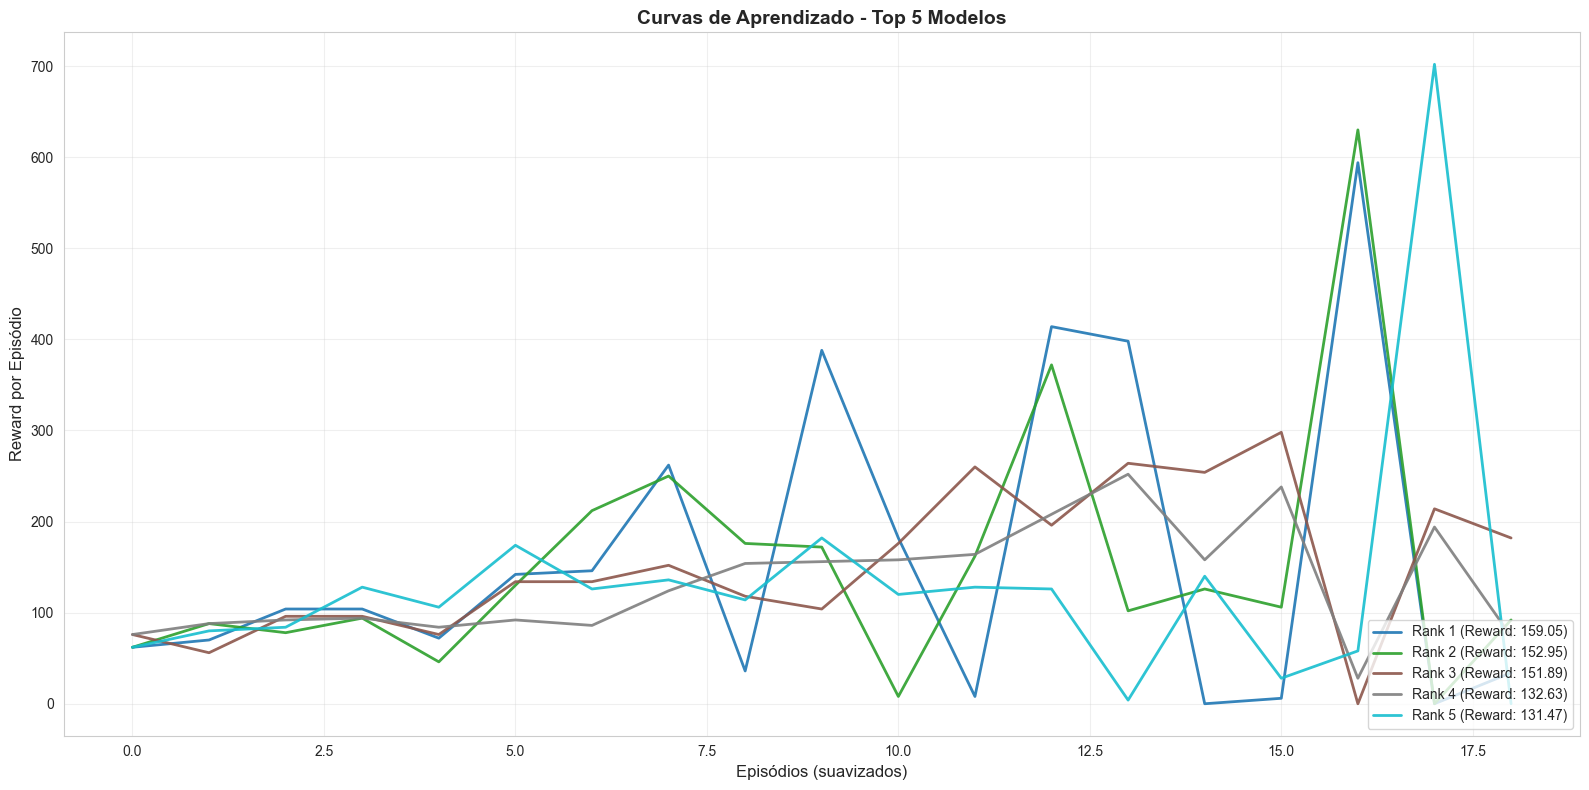


4.2 - RANKING E DISTRIBUIÇÃO DE PERFORMANCE


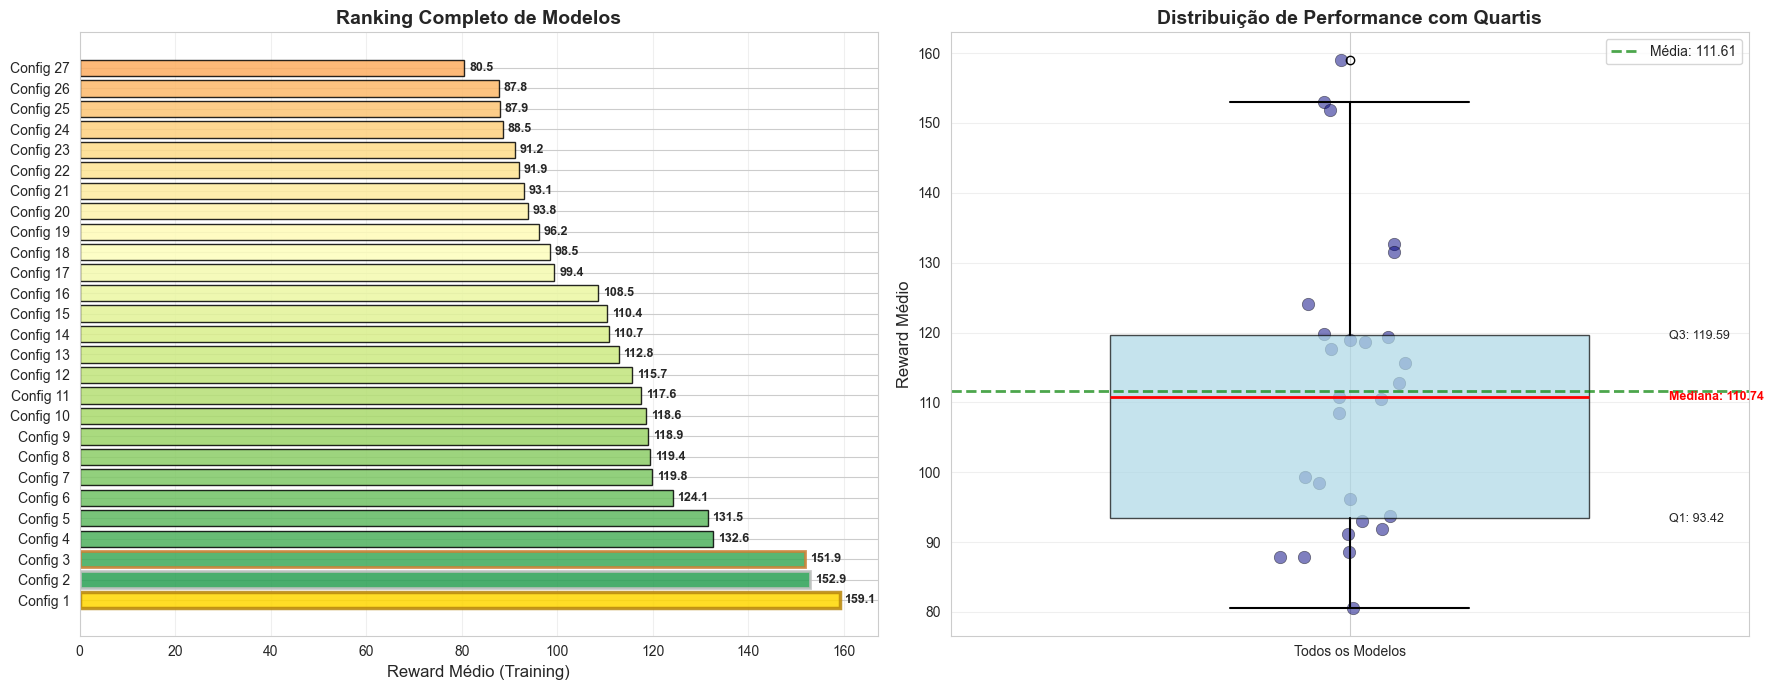


4.3 - ANÁLISE DE HIPERPARÂMETROS


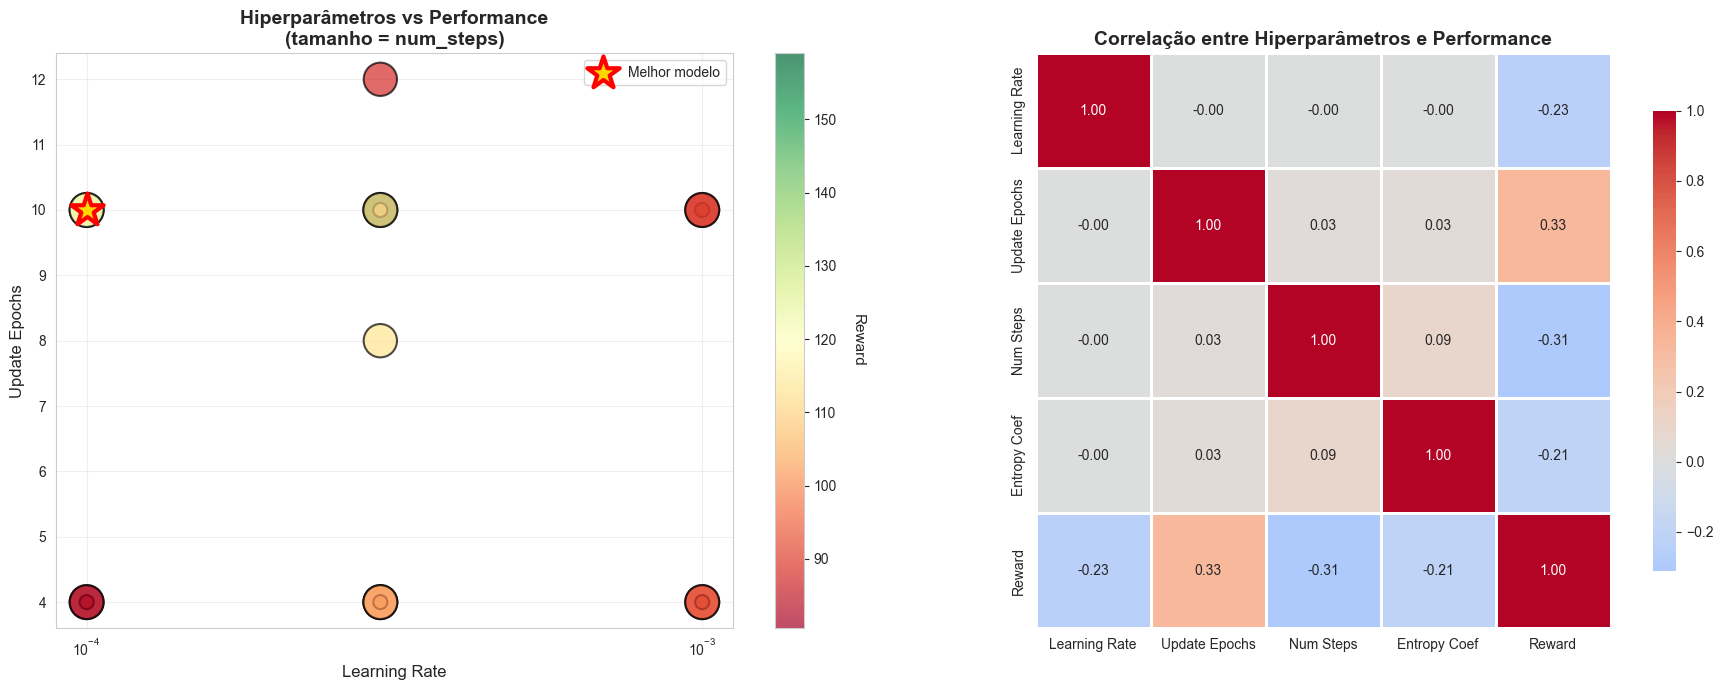


ESTATÍSTICAS RESUMIDAS (Training)
Métrica                   Valor
--------------------------------
Melhor reward:           159.05
Pior reward:              80.53
Reward médio:            111.61
Desvio padrão:            21.06
Mediana:                 110.74
Q1 (25%):                 93.42
Q3 (75%):                119.59
Amplitude:                78.53
IQR (Q3-Q1):              26.17
CV (%):                   18.87


In [115]:
if models_info:
    config_models = df_models[df_models['type'] == 'config']
    
    # ==============================================================================
    # SEÇÃO 4.1: CURVAS DE APRENDIZADO (Top 5 modelos)
    # ==============================================================================
    print("=" * 80)
    print("4.1 - CURVAS DE APRENDIZADO (Top 5 Modelos)")
    print("=" * 80)
    
    top_n = min(5, len(config_models))
    fig, ax = plt.subplots(figsize=(16, 8))
    
    colors = plt.cm.tab10(np.linspace(0, 1, top_n))
    
    for i in range(top_n):
        model_row = config_models.iloc[i]
        episode_rewards = model_row['episode_rewards']
        
        if episode_rewards and len(episode_rewards) > 0:
            # Suaviza a curva com média móvel
            window = min(100, len(episode_rewards) // 10)
            if window > 0:
                smoothed = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
                x = np.arange(len(smoothed))
                
                # Linha suavizada
                ax.plot(x, smoothed, color=colors[i], linewidth=2, 
                       label=f"Rank {i+1} (Reward: {model_row['reward']:.2f})", alpha=0.9)
                
                # Banda de variação (opcional - apenas para top 3)
                if i < 3:
                    # Calcula desvio padrão móvel
                    std_window = []
                    for j in range(len(smoothed)):
                        start = max(0, j - window // 2)
                        end = min(len(episode_rewards), j + window // 2)
                        std_window.append(np.std(episode_rewards[start:end]))
                    
                    ax.fill_between(x, 
                                   smoothed - np.array(std_window[:len(smoothed)]),
                                   smoothed + np.array(std_window[:len(smoothed)]),
                                   color=colors[i], alpha=0.15)
    
    ax.set_xlabel('Episódios (suavizados)', fontsize=12)
    ax.set_ylabel('Reward por Episódio', fontsize=12)
    ax.set_title('Curvas de Aprendizado - Top 5 Modelos', fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('midia/learning_curves_top5.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # ==============================================================================
    # SEÇÃO 4.2: RANKING E DISTRIBUIÇÃO
    # ==============================================================================
    print("\n" + "=" * 80)
    print("4.2 - RANKING E DISTRIBUIÇÃO DE PERFORMANCE")
    print("=" * 80)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    
    # 4.2.1: Ranking horizontal (mais claro)
    if len(config_models) > 0:
        model_names = [f"Config {i+1}" for i in range(len(config_models))]
        y_pos = np.arange(len(config_models))
        
        # Cores gradientes
        colors_grad = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(config_models)))
        
        bars = ax1.barh(y_pos, config_models['reward'], 
                       color=colors_grad[::-1],  # Inverte para melhor no topo
                       edgecolor='black', linewidth=1, alpha=0.85)
        
        # Destaca top 3
        bars[0].set_color('gold')
        bars[0].set_edgecolor('darkgoldenrod')
        bars[0].set_linewidth(2.5)
        
        if len(bars) > 1:
            bars[1].set_edgecolor('silver')
            bars[1].set_linewidth(2)
        if len(bars) > 2:
            bars[2].set_edgecolor('#CD7F32')  # Bronze
            bars[2].set_linewidth(2)
        
        ax1.set_yticks(y_pos)
        ax1.set_yticklabels(model_names)
        ax1.set_xlabel('Reward Médio (Training)', fontsize=12)
        ax1.set_title('Ranking Completo de Modelos', fontsize=14, fontweight='bold')
        ax1.grid(True, alpha=0.3, axis='x')
        
        # Adiciona valores nas barras
        for i, (bar, reward) in enumerate(zip(bars, config_models['reward'])):
            ax1.text(reward + 1, bar.get_y() + bar.get_height()/2, 
                    f'{reward:.1f}', 
                    va='center', fontsize=9, fontweight='bold')
    
    # 4.2.2: Box Plot de distribuição
    if len(config_models) > 0:
        bp = ax2.boxplot([config_models['reward']], 
                         vert=True, patch_artist=True, widths=0.6,
                         boxprops=dict(facecolor='lightblue', alpha=0.7),
                         medianprops=dict(color='red', linewidth=2),
                         whiskerprops=dict(linewidth=1.5),
                         capprops=dict(linewidth=1.5))
        
        # Adiciona pontos individuais
        y_scatter = config_models['reward'].values
        x_scatter = np.random.normal(1, 0.04, size=len(y_scatter))
        ax2.scatter(x_scatter, y_scatter, alpha=0.5, s=80, color='navy', edgecolor='black', linewidth=0.5)
        
        # Estatísticas
        q1 = config_models['reward'].quantile(0.25)
        q3 = config_models['reward'].quantile(0.75)
        median = config_models['reward'].median()
        mean = config_models['reward'].mean()
        
        ax2.axhline(mean, color='green', linestyle='--', linewidth=2, alpha=0.7, label=f'Média: {mean:.2f}')
        
        ax2.set_ylabel('Reward Médio', fontsize=12)
        ax2.set_title('Distribuição de Performance com Quartis', fontsize=14, fontweight='bold')
        ax2.set_xticks([1])
        ax2.set_xticklabels(['Todos os Modelos'])
        ax2.legend(loc='upper right')
        ax2.grid(True, alpha=0.3, axis='y')
        
        # Anotações
        ax2.text(1.4, q1, f'Q1: {q1:.2f}', va='center', fontsize=9)
        ax2.text(1.4, median, f'Mediana: {median:.2f}', va='center', fontsize=9, color='red', fontweight='bold')
        ax2.text(1.4, q3, f'Q3: {q3:.2f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.savefig('midia/ranking_distribuicao.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # ==============================================================================
    # SEÇÃO 4.3: ANÁLISE DE HIPERPARÂMETROS
    # ==============================================================================
    print("\n" + "=" * 80)
    print("4.3 - ANÁLISE DE HIPERPARÂMETROS")
    print("=" * 80)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    
    if len(config_models) > 0 and 'config' in config_models.columns:
        try:
            # Extrai hiperparâmetros
            learning_rates = np.array([cfg.get('learning_rate', 0) for cfg in config_models['config']])
            update_epochs = np.array([cfg.get('update_epochs', 0) for cfg in config_models['config']])
            num_steps = np.array([cfg.get('num_steps', 0) for cfg in config_models['config']])
            ent_coefs = np.array([cfg.get('ent_coef', 0) for cfg in config_models['config']])
            rewards = config_models['reward'].values
            
            # 4.3.1: Scatter 3D-like (Learning Rate vs Update Epochs, tamanho = num_steps)
            sizes = (num_steps - num_steps.min() + 1) / (num_steps.max() - num_steps.min() + 1) * 500 + 100
            
            scatter = ax1.scatter(learning_rates, update_epochs, 
                                 c=rewards, s=sizes,
                                 cmap='RdYlGn', alpha=0.7, 
                                 edgecolor='black', linewidth=1.5)
            
            ax1.set_xlabel('Learning Rate', fontsize=12)
            ax1.set_ylabel('Update Epochs', fontsize=12)
            ax1.set_title('Hiperparâmetros vs Performance\n(tamanho = num_steps)', 
                         fontsize=14, fontweight='bold')
            ax1.set_xscale('log')
            
            cbar = plt.colorbar(scatter, ax=ax1)
            cbar.set_label('Reward', rotation=270, labelpad=20, fontsize=11)
            
            # Marca o melhor
            best_idx_local = np.argmax(rewards)
            ax1.scatter(learning_rates[best_idx_local], update_epochs[best_idx_local], 
                       s=600, marker='*', color='gold', 
                       edgecolor='red', linewidth=3, zorder=10,
                       label='Melhor modelo')
            ax1.legend(fontsize=10)
            ax1.grid(True, alpha=0.3)
            
            # 4.3.2: Heatmap de correlação (se houver variação suficiente)
            param_data = pd.DataFrame({
                'Learning Rate': np.log10(learning_rates),  # Log scale
                'Update Epochs': update_epochs,
                'Num Steps': num_steps,
                'Entropy Coef': ent_coefs,
                'Reward': rewards
            })
            
            corr_matrix = param_data.corr()
            
            sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                       center=0, square=True, linewidths=1, 
                       cbar_kws={"shrink": 0.8}, ax=ax2)
            
            ax2.set_title('Correlação entre Hiperparâmetros e Performance', 
                         fontsize=14, fontweight='bold')
            
        except Exception as e:
            ax1.text(0.5, 0.5, f'Erro ao processar\nhiperparâmetros:\n{str(e)[:50]}', 
                    ha='center', va='center', transform=ax1.transAxes, fontsize=11)
            ax2.text(0.5, 0.5, 'Dados insuficientes\npara heatmap', 
                    ha='center', va='center', transform=ax2.transAxes, fontsize=11)
    else:
        ax1.text(0.5, 0.5, 'Configurações não disponíveis', 
                ha='center', va='center', transform=ax1.transAxes, fontsize=12)
        ax2.text(0.5, 0.5, 'Configurações não disponíveis', 
                ha='center', va='center', transform=ax2.transAxes, fontsize=12)
    
    plt.tight_layout()
    plt.savefig('midia/hiperparametros_analise.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # ==============================================================================
    # ESTATÍSTICAS RESUMIDAS
    # ==============================================================================
    print("\n" + "=" * 80)
    print("ESTATÍSTICAS RESUMIDAS (Training)")
    print("=" * 80)
    
    if len(config_models) > 0:
        stats = config_models['reward'].describe()
        print(f"{'Métrica':<20} {'Valor':>10}")
        print("-" * 32)
        print(f"{'Melhor reward:':<20} {stats['max']:>10.2f}")
        print(f"{'Pior reward:':<20} {stats['min']:>10.2f}")
        print(f"{'Reward médio:':<20} {stats['mean']:>10.2f}")
        print(f"{'Desvio padrão:':<20} {stats['std']:>10.2f}")
        print(f"{'Mediana:':<20} {stats['50%']:>10.2f}")
        print(f"{'Q1 (25%):':<20} {stats['25%']:>10.2f}")
        print(f"{'Q3 (75%):':<20} {stats['75%']:>10.2f}")
        print(f"{'Amplitude:':<20} {stats['max'] - stats['min']:>10.2f}")
        print(f"{'IQR (Q3-Q1):':<20} {stats['75%'] - stats['25%']:>10.2f}")
        
        # Coeficiente de variação
        cv = (stats['std'] / stats['mean']) * 100 if stats['mean'] != 0 else 0
        print(f"{'CV (%):':<20} {cv:>10.2f}")
        
else:
    print("Sem modelos para analisar")

## 5. Avaliação Detalhada dos Modelos

In [116]:
def load_and_evaluate_model(model_path: str, env, num_episodes: int = 10, max_steps: int = 300) -> Dict:
    # Carrega checkpoint - CORREÇÃO: weights_only=False
    checkpoint = torch.load(model_path, map_location=device, weights_only=False)
    model_info = {
        'config': checkpoint.get('config', {}),
        'reward': checkpoint.get('reward', 0.0),
        'total_episodes': len(checkpoint.get('episode_rewards', []))
    }
    
    # Cria e carrega o modelo
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    agent.load_state_dict(checkpoint['model_state_dict'])
    agent.eval()
    
    # Avalia performance
    episode_rewards = []
    episode_lengths = []
    episode_info = []
    
    with torch.no_grad():
        for episode in range(num_episodes):
            obs, _ = env.reset()
            episode_reward = 0
            steps = 0
            
            done = False
            while not done and steps < max_steps:
                obs_tensor = torch.FloatTensor(obs).unsqueeze(0).to(device)
                action, _, _, _ = agent.get_action_and_value(obs_tensor)
                
                obs, reward, terminated, truncated, info = env.step(action.cpu().item())
                done = terminated or truncated
                
                episode_reward += reward
                steps += 1
            
            episode_rewards.append(episode_reward)
            episode_lengths.append(steps)
            episode_info.append({'reward': episode_reward, 'length': steps})
    
    # Calcula estatísticas
    results = {
        'model_path': model_path,
        'training_info': model_info,
        'eval_episodes': num_episodes,
        'eval_rewards': episode_rewards,
        'eval_lengths': episode_lengths,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'std_length': np.std(episode_lengths),
        'success_rate': np.mean([r > -50 for r in episode_rewards]),
    }
    
    return results, agent

# Configura ambiente para avaliação
eval_env = OvercookedMARL(
    render_mode=None,
    map_path="overcooked_marl_env/map/maps/simple_map.txt",
    num_fixed_agents=1,
    verbose=False
)
eval_env = PettingZooToGymWrapper(eval_env)

[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


Avaliando 10 modelo(s)...


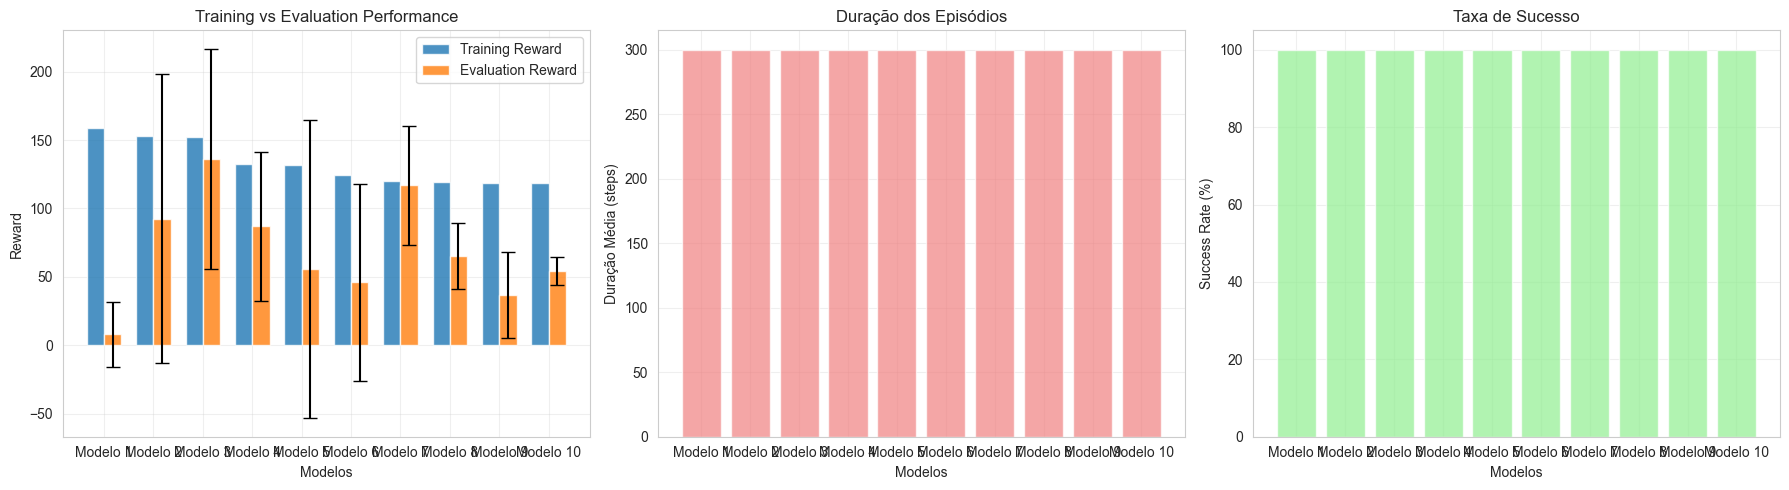

Model       | Train Reward | Eval Reward  | Eval Length | Success Rate
----------------------------------------------------------------------
Modelo  1   |      159.05 |    8.00±23.66 |      300.0 |      100.0%
Modelo  2   |      152.95 |   92.60±105.81 |      300.0 |      100.0%
Modelo  3   |      151.89 |   136.20±80.50 |      300.0 |      100.0%
Modelo  4   |      132.63 |   86.90±54.51 |      300.0 |      100.0%
Modelo  5   |      131.47 |   55.70±109.17 |      300.0 |      100.0%
Modelo  6   |      124.11 |   45.90±71.80 |      300.0 |      100.0%
Modelo  7   |      119.79 |   116.90±43.31 |      300.0 |      100.0%
Modelo  8   |      119.40 |   65.40±24.13 |      300.0 |      100.0%
Modelo  9   |      118.95 |   36.80±31.47 |      300.0 |      100.0%
Modelo 10   |      118.63 |   54.10±10.40 |      300.0 |      100.0%


In [117]:
# Avalia todos os modelos encontrados (ou configure o número desejado)
if models_info and len(df_models) > 0:
    # Opções:
    # - min(10, len(df_models))  -> Avalia até 10 melhores
    # - len(df_models)           -> Avalia TODOS os modelos
    # - 3                        -> Avalia apenas top 3
    num_models_to_evaluate = min(10, len(df_models))  # Avalia até 10 modelos
    
    print(f"Avaliando {num_models_to_evaluate} modelo(s)...")
    evaluation_results = []
    
    for i in range(num_models_to_evaluate):
        model_row = df_models.iloc[i]
        model_path = model_row['path']
        
        try:
            results, agent = load_and_evaluate_model(model_path, eval_env, num_episodes=20)
            evaluation_results.append(results)
            
        except Exception as e:
            print(f"Erro na avaliação do modelo {i+1}: {e}")
    
    # Gráfico comparativo das avaliações
    if evaluation_results:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # Dados para plots
        model_names = [f"Modelo {i+1}" for i in range(len(evaluation_results))]
        training_rewards = [df_models.iloc[i]['reward'] for i in range(len(evaluation_results))]
        eval_means = [r['mean_reward'] for r in evaluation_results]
        eval_stds = [r['std_reward'] for r in evaluation_results]
        eval_lengths = [r['mean_length'] for r in evaluation_results]
        success_rates = [r['success_rate'] for r in evaluation_results]
        
        # 1. Comparação Training vs Evaluation
        x = np.arange(len(model_names))
        width = 0.35
        
        axes[0].bar(x - width/2, training_rewards, width, label='Training Reward', alpha=0.8)
        axes[0].bar(x + width/2, eval_means, width, yerr=eval_stds, 
                   label='Evaluation Reward', alpha=0.8, capsize=5)
        
        axes[0].set_xlabel('Modelos')
        axes[0].set_ylabel('Reward')
        axes[0].set_title('Training vs Evaluation Performance')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(model_names)
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
        
        # 2. Episode Length
        axes[1].bar(model_names, eval_lengths, color='lightcoral', alpha=0.7)
        axes[1].set_xlabel('Modelos')
        axes[1].set_ylabel('Duração Média (steps)')
        axes[1].set_title('Duração dos Episódios')
        axes[1].grid(True, alpha=0.3)
        
        # 3. Success Rate
        axes[2].bar(model_names, [s*100 for s in success_rates], color='lightgreen', alpha=0.7)
        axes[2].set_xlabel('Modelos')
        axes[2].set_ylabel('Success Rate (%)')
        axes[2].set_title('Taxa de Sucesso')
        axes[2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('midia/comparacao_avaliacao_modelos.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        # Tabela resumo
        print("Model       | Train Reward | Eval Reward  | Eval Length | Success Rate")
        print("-" * 70)
        for i, (result, train_r) in enumerate(zip(evaluation_results, training_rewards)):
            print(f"Modelo {i+1:2d}   |     {train_r:7.2f} |   {result['mean_reward']:5.2f}±{result['std_reward']:4.2f} |    {result['mean_length']:7.1f} |      {result['success_rate']:5.1%}")

else:
    print("Nenhum modelo encontrado para avaliação. Execute primeiro o treinamento.")


5.1 - ANÁLISE AVANÇADA DE AVALIAÇÃO


C:\Users\thais\AppData\Local\Temp\ipykernel_12052\804708846.py:96: RankWarning: Polyfit may be poorly conditioned
  z = np.polyfit(eval_lengths, eval_means, 1)


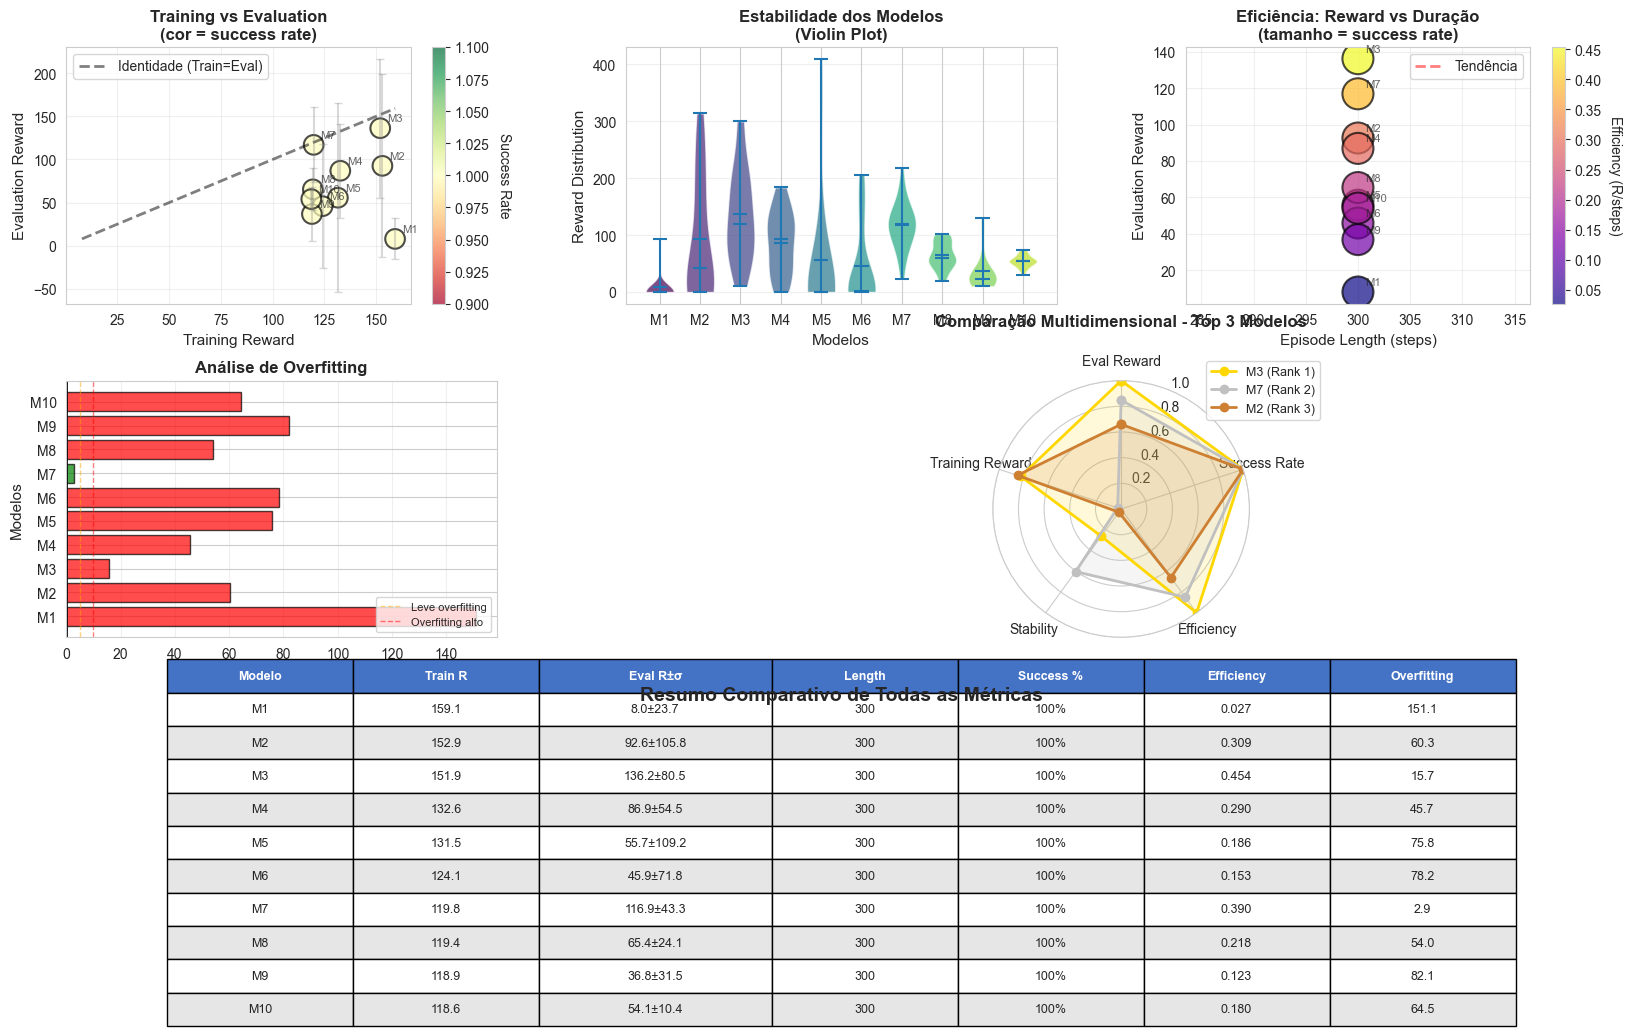


MÉTRICAS CONSOLIDADAS

🏆 Melhor Avaliação:       M3 (Reward: 136.20)
📊 Mais Estável:           M10 (σ: 10.40)
⚡ Mais Eficiente:         M3 (Eff: 0.4540)
✅ Menos Overfitting:      M7 (Score: 2.89)

📈 Overfitting Médio:      63.04
📉 Estabilidade Média (σ): 55.48

⚖️  Modelo Mais Balanceado: M7


In [118]:
# ==============================================================================
# SEÇÃO 5.1: GRÁFICOS AVANÇADOS DE AVALIAÇÃO
# ==============================================================================

if 'evaluation_results' in locals() and evaluation_results and len(evaluation_results) > 0:
    print("\n" + "=" * 80)
    print("5.1 - ANÁLISE AVANÇADA DE AVALIAÇÃO")
    print("=" * 80)
    
    fig = plt.figure(figsize=(20, 12))
    gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)
    
    # Prepara dados
    n_models = len(evaluation_results)
    model_names = [f"M{i+1}" for i in range(n_models)]
    train_rewards = [df_models.iloc[i]['reward'] for i in range(n_models)]
    eval_means = [r['mean_reward'] for r in evaluation_results]
    eval_stds = [r['std_reward'] for r in evaluation_results]
    eval_lengths = [r['mean_length'] for r in evaluation_results]
    success_rates = [r['success_rate'] for r in evaluation_results]
    
    # Calcula métricas adicionais
    overfitting_scores = [(train - eval) for train, eval in zip(train_rewards, eval_means)]
    efficiencies = [reward / length if length > 0 else 0 
                   for reward, length in zip(eval_means, eval_lengths)]
    
    # ==============================================================================
    # 5.1.1: Training vs Evaluation (Scatter com linha de identidade)
    # ==============================================================================
    ax1 = fig.add_subplot(gs[0, 0])
    
    # Scatter plot
    scatter = ax1.scatter(train_rewards, eval_means, s=200, alpha=0.7, 
                         c=success_rates, cmap='RdYlGn', 
                         edgecolor='black', linewidth=1.5)
    
    # Linha de identidade (x=y)
    min_val = min(min(train_rewards), min(eval_means))
    max_val = max(max(train_rewards), max(eval_means))
    ax1.plot([min_val, max_val], [min_val, max_val], 'k--', 
            alpha=0.5, linewidth=2, label='Identidade (Train=Eval)')
    
    # Barras de erro
    ax1.errorbar(train_rewards, eval_means, yerr=eval_stds, 
                fmt='none', ecolor='gray', alpha=0.3, capsize=3)
    
    # Anota modelos
    for i, name in enumerate(model_names):
        ax1.annotate(name, (train_rewards[i], eval_means[i]), 
                    xytext=(5, 5), textcoords='offset points', 
                    fontsize=8, alpha=0.7)
    
    ax1.set_xlabel('Training Reward', fontsize=11)
    ax1.set_ylabel('Evaluation Reward', fontsize=11)
    ax1.set_title('Training vs Evaluation\n(cor = success rate)', fontsize=12, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    cbar1 = plt.colorbar(scatter, ax=ax1)
    cbar1.set_label('Success Rate', rotation=270, labelpad=15)
    
    # ==============================================================================
    # 5.1.2: Violin Plot - Distribuição de Rewards por Modelo
    # ==============================================================================
    ax2 = fig.add_subplot(gs[0, 1])
    
    # Prepara dados para violin plot
    all_eval_rewards = [r['eval_rewards'] for r in evaluation_results]
    
    parts = ax2.violinplot(all_eval_rewards, positions=range(n_models), 
                          showmeans=True, showmedians=True, widths=0.7)
    
    # Colorir violins
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(plt.cm.viridis(i / n_models))
        pc.set_alpha(0.7)
    
    ax2.set_xlabel('Modelos', fontsize=11)
    ax2.set_ylabel('Reward Distribution', fontsize=11)
    ax2.set_title('Estabilidade dos Modelos\n(Violin Plot)', fontsize=12, fontweight='bold')
    ax2.set_xticks(range(n_models))
    ax2.set_xticklabels(model_names)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # ==============================================================================
    # 5.1.3: Scatter - Eficiência (Reward/Steps)
    # ==============================================================================
    ax3 = fig.add_subplot(gs[0, 2])
    
    scatter3 = ax3.scatter(eval_lengths, eval_means, s=np.array(success_rates)*500, 
                          c=efficiencies, cmap='plasma', alpha=0.7,
                          edgecolor='black', linewidth=1.5)
    
    # Linha de tendência
    if len(eval_lengths) > 1:
        z = np.polyfit(eval_lengths, eval_means, 1)
        p = np.poly1d(z)
        x_trend = np.linspace(min(eval_lengths), max(eval_lengths), 100)
        ax3.plot(x_trend, p(x_trend), "r--", alpha=0.5, linewidth=2, label='Tendência')
    
    # Anota modelos
    for i, name in enumerate(model_names):
        ax3.annotate(name, (eval_lengths[i], eval_means[i]), 
                    xytext=(5, 5), textcoords='offset points', 
                    fontsize=8, alpha=0.7)
    
    ax3.set_xlabel('Episode Length (steps)', fontsize=11)
    ax3.set_ylabel('Evaluation Reward', fontsize=11)
    ax3.set_title('Eficiência: Reward vs Duração\n(tamanho = success rate)', 
                 fontsize=12, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    cbar3 = plt.colorbar(scatter3, ax=ax3)
    cbar3.set_label('Efficiency (R/steps)', rotation=270, labelpad=15)
    
    # ==============================================================================
    # 5.1.4: Overfitting Score (Train - Eval)
    # ==============================================================================
    ax4 = fig.add_subplot(gs[1, 0])
    
    colors_overfit = ['red' if score > 10 else 'orange' if score > 5 else 'green' 
                     for score in overfitting_scores]
    
    bars = ax4.barh(model_names, overfitting_scores, color=colors_overfit, 
                   alpha=0.7, edgecolor='black', linewidth=1)
    
    ax4.axvline(0, color='black', linewidth=2)
    ax4.axvline(5, color='orange', linestyle='--', linewidth=1, alpha=0.5, label='Leve overfitting')
    ax4.axvline(10, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Overfitting alto')
    
    ax4.set_xlabel('Overfitting Score (Train - Eval)', fontsize=11)
    ax4.set_ylabel('Modelos', fontsize=11)
    ax4.set_title('Análise de Overfitting', fontsize=12, fontweight='bold')
    ax4.legend(loc='lower right', fontsize=8)
    ax4.grid(True, alpha=0.3, axis='x')
    
    # ==============================================================================
    # 5.1.5: Radar Chart - Top 3 Modelos
    # ==============================================================================
    ax5 = fig.add_subplot(gs[1, 1:], projection='polar')
    
    # Seleciona top 3 por evaluation reward
    top_3_indices = np.argsort(eval_means)[-3:][::-1]
    
    # Métricas para o radar (normalizadas)
    categories = ['Eval Reward', 'Success Rate', 'Efficiency', 'Stability', 'Training Reward']
    num_vars = len(categories)
    
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]
    
    ax5.set_theta_offset(np.pi / 2)
    ax5.set_theta_direction(-1)
    ax5.set_xticks(angles[:-1])
    ax5.set_xticklabels(categories, fontsize=10)
    
    colors_radar = ['gold', 'silver', '#CD7F32']
    
    for rank, idx in enumerate(top_3_indices):
        # Normaliza métricas [0, 1]
        eval_r_norm = (eval_means[idx] - min(eval_means)) / (max(eval_means) - min(eval_means) + 1e-6)
        success_norm = success_rates[idx]
        eff_norm = (efficiencies[idx] - min(efficiencies)) / (max(efficiencies) - min(efficiencies) + 1e-6)
        stability_norm = 1 - (eval_stds[idx] / (max(eval_stds) + 1e-6))  # Menor std = melhor
        train_r_norm = (train_rewards[idx] - min(train_rewards)) / (max(train_rewards) - min(train_rewards) + 1e-6)
        
        values = [eval_r_norm, success_norm, eff_norm, stability_norm, train_r_norm]
        values += values[:1]
        
        ax5.plot(angles, values, 'o-', linewidth=2, label=f'{model_names[idx]} (Rank {rank+1})', 
                color=colors_radar[rank])
        ax5.fill(angles, values, alpha=0.15, color=colors_radar[rank])
    
    ax5.set_ylim(0, 1)
    ax5.set_title('Comparação Multidimensional - Top 3 Modelos', 
                 fontsize=12, fontweight='bold', pad=20)
    ax5.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=9)
    ax5.grid(True)
    
    # ==============================================================================
    # 5.1.6: Tabela de Métricas Detalhadas
    # ==============================================================================
    ax6 = fig.add_subplot(gs[2, :])
    ax6.axis('off')
    
    # Prepara dados da tabela
    table_data = []
    headers = ['Modelo', 'Train R', 'Eval R±σ', 'Length', 'Success %', 'Efficiency', 'Overfitting']
    
    for i in range(n_models):
        row = [
            model_names[i],
            f"{train_rewards[i]:.1f}",
            f"{eval_means[i]:.1f}±{eval_stds[i]:.1f}",
            f"{eval_lengths[i]:.0f}",
            f"{success_rates[i]*100:.0f}%",
            f"{efficiencies[i]:.3f}",
            f"{overfitting_scores[i]:.1f}"
        ]
        table_data.append(row)
    
    # Cria tabela
    table = ax6.table(cellText=table_data, colLabels=headers, 
                     cellLoc='center', loc='center',
                     colWidths=[0.12, 0.12, 0.15, 0.12, 0.12, 0.12, 0.12])
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2)
    
    # Colorir header
    for i in range(len(headers)):
        table[(0, i)].set_facecolor('#4472C4')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    # Colorir linhas alternadas
    for i in range(1, len(table_data) + 1):
        for j in range(len(headers)):
            if i % 2 == 0:
                table[(i, j)].set_facecolor('#E7E6E6')
    
    ax6.set_title('Resumo Comparativo de Todas as Métricas', 
                 fontsize=14, fontweight='bold', pad=10)
    
    plt.savefig('midia/analise_avancada_avaliacao.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # ==============================================================================
    # ESTATÍSTICAS FINAIS
    # ==============================================================================
    print("\n" + "=" * 80)
    print("MÉTRICAS CONSOLIDADAS")
    print("=" * 80)
    
    best_eval_idx = np.argmax(eval_means)
    most_stable_idx = np.argmin(eval_stds)
    most_efficient_idx = np.argmax(efficiencies)
    least_overfit_idx = np.argmin(overfitting_scores)
    
    print(f"\n🏆 Melhor Avaliação:       {model_names[best_eval_idx]} (Reward: {eval_means[best_eval_idx]:.2f})")
    print(f"📊 Mais Estável:           {model_names[most_stable_idx]} (σ: {eval_stds[most_stable_idx]:.2f})")
    print(f"⚡ Mais Eficiente:         {model_names[most_efficient_idx]} (Eff: {efficiencies[most_efficient_idx]:.4f})")
    print(f"✅ Menos Overfitting:      {model_names[least_overfit_idx]} (Score: {overfitting_scores[least_overfit_idx]:.2f})")
    
    avg_overfitting = np.mean(overfitting_scores)
    avg_stability = np.mean(eval_stds)
    
    print(f"\n📈 Overfitting Médio:      {avg_overfitting:.2f}")
    print(f"📉 Estabilidade Média (σ): {avg_stability:.2f}")
    
    # Identifica melhor modelo balanceado (menor distância euclidiana ao ideal)
    # Normaliza métricas
    eval_means_norm = np.array(eval_means) / max(eval_means)
    stability_norm = 1 - (np.array(eval_stds) / max(eval_stds))
    efficiency_norm = np.array(efficiencies) / max(efficiencies)
    overfit_norm = 1 - (np.array(overfitting_scores) / max(overfitting_scores))
    
    # Ideal: (1, 1, 1, 1)
    distances = np.sqrt((1-eval_means_norm)**2 + (1-stability_norm)**2 + 
                       (1-efficiency_norm)**2 + (1-overfit_norm)**2)
    
    best_balanced_idx = np.argmin(distances)
    print(f"\n⚖️  Modelo Mais Balanceado: {model_names[best_balanced_idx]}")
    
else:
    print("Execute a célula de avaliação primeiro para ver análises avançadas.")

## 6. Visualização do Comportamento dos Modelos


Visualizando o melhor modelo avaliado (índice 3):
- Arquivo: config_15_reward_151.89.pth
- Reward de treinamento: 151.89
- Reward de avaliação: 136.20
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


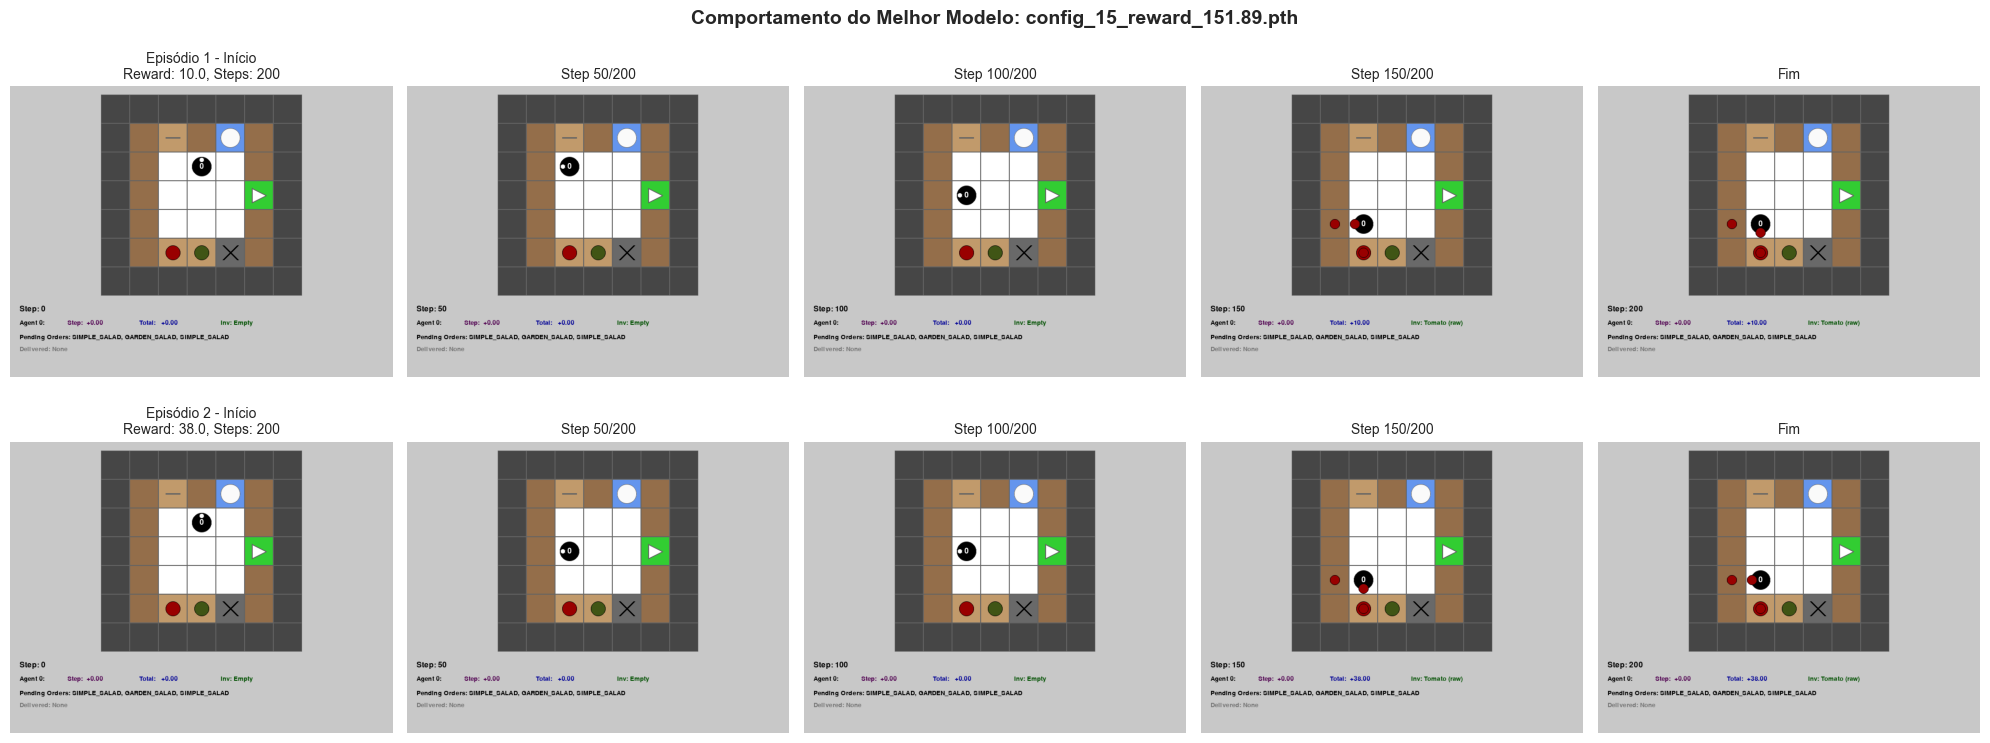

In [119]:
def visualize_model_behavior(model_path: str, num_episodes: int = 2, max_steps: int = 200):
    # Carrega modelo - CORREÇÃO: weights_only=False
    checkpoint = torch.load(model_path, map_location=device, weights_only=False)
    agent = ActorCritic(eval_env.observation_space, eval_env.action_space).to(device)
    agent.load_state_dict(checkpoint['model_state_dict'])
    agent.eval()
    
    # Cria ambiente com renderização
    viz_env = OvercookedMARL(
        render_mode="rgb_array",
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    viz_env = PettingZooToGymWrapper(viz_env)
    
    all_frames = []
    episodes_info = []
    
    with torch.no_grad():
        for episode in range(num_episodes):
            obs, _ = viz_env.reset()
            episode_frames = []
            episode_reward = 0
            steps = 0
            
            # Frame inicial
            frame = viz_env.env.render()
            if frame is not None:
                episode_frames.append(frame)
            
            done = False
            while not done and steps < max_steps:
                obs_tensor = torch.FloatTensor(obs).unsqueeze(0).to(device)
                action, _, _, _ = agent.get_action_and_value(obs_tensor)
                
                obs, reward, terminated, truncated, info = viz_env.step(action.cpu().item())
                done = terminated or truncated
                
                episode_reward += reward
                steps += 1
                
                frame = viz_env.env.render()
                if frame is not None:
                    episode_frames.append(frame)
            
            all_frames.append(episode_frames)
            episodes_info.append({
                'episode': episode + 1,
                'reward': episode_reward,
                'steps': steps
            })
    
    viz_env.close()
    return all_frames, episodes_info

# Visualiza modelos avaliados
# Opções: 
# - 0: melhor modelo (maior reward de avaliação)
# - [0, 1, 2]: múltiplos modelos
if 'evaluation_results' in locals() and evaluation_results:
    # Identifica o MELHOR modelo baseado na avaliação (não no training)
    best_eval_idx = np.argmax([r['mean_reward'] for r in evaluation_results])
    best_model_path = df_models.iloc[best_eval_idx]['path']
    best_model_name = df_models.iloc[best_eval_idx]['filename']
    
    print(f"\nVisualizando o melhor modelo avaliado (índice {best_eval_idx + 1}):")
    print(f"- Arquivo: {best_model_name}")
    print(f"- Reward de treinamento: {df_models.iloc[best_eval_idx]['reward']:.2f}")
    print(f"- Reward de avaliação: {evaluation_results[best_eval_idx]['mean_reward']:.2f}")
    
    try:
        frames, episodes_info = visualize_model_behavior(best_model_path, num_episodes=2)
        
        # Plot dos frames
        num_episodes_viz = len(frames)
        fig, axes = plt.subplots(num_episodes_viz, 5, figsize=(20, 4 * num_episodes_viz))
        
        if num_episodes_viz == 1:
            axes = [axes]
        
        for episode_idx, (episode_frames, info) in enumerate(zip(frames, episodes_info)):
            if len(episode_frames) == 0:
                continue
            
            # 5 frames igualmente espaçados
            indices = np.linspace(0, len(episode_frames) - 1, 5, dtype=int)
            
            for col_idx, frame_idx in enumerate(indices):
                ax = axes[episode_idx][col_idx] if num_episodes_viz > 1 else axes[col_idx]
                ax.imshow(episode_frames[frame_idx])
                ax.axis('off')
                
                if col_idx == 0:
                    ax.set_title(f"Episódio {info['episode']} - Início\n"
                                f"Reward: {info['reward']:.1f}, Steps: {info['steps']}", 
                                fontsize=10)
                elif col_idx == len(indices) - 1:
                    ax.set_title(f"Fim", fontsize=10)
                else:
                    ax.set_title(f"Step {frame_idx}/{len(episode_frames)-1}", fontsize=10)
        
        plt.suptitle(f'Comportamento do Melhor Modelo: {best_model_name}', 
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('midia/visualizacao_melhor_modelo.png', dpi=150, bbox_inches='tight')
        plt.show()
        
    except Exception as e:
        print(f"Erro na visualização: {e}")

else:
    print("Execute a avaliação dos modelos primeiro.")


6.1 - COMPARAÇÃO VISUAL: MELHOR vs PIOR MODELO

🥇 MELHOR: config_15_reward_151.89.pth (Reward: 136.20)
🔻 PIOR:   config_03_reward_159.05.pth (Reward: 8.00)
📊 Delta:  128.20

Gerando visualizações comparativas...
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


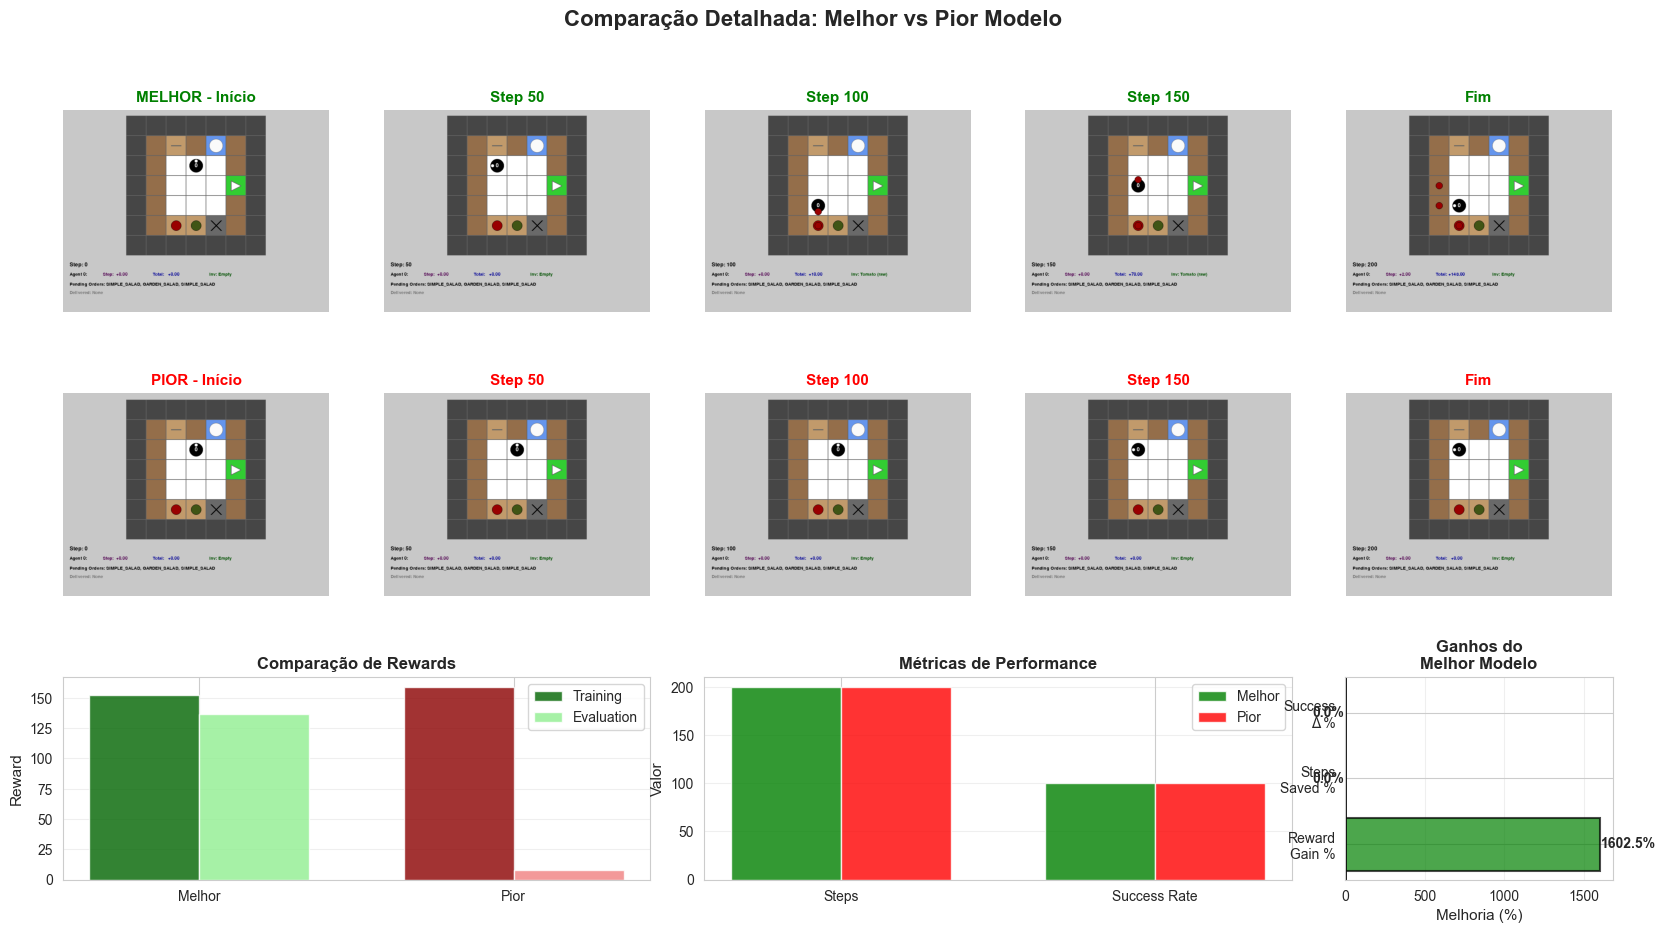


ANÁLISE COMPARATIVA

📊 Diferença de Performance:
  • Reward:       136.20 vs 8.00 (+1602.5%)
  • Steps:        200 vs 200 (-0.0% eficiência)
  • Success Rate: 100.0% vs 100.0% (+0.0%)

💡 Insights:
  ✓ Ganho substancial de performance (1602.5%)


In [120]:
# ==============================================================================
# SEÇÃO 6.1: COMPARAÇÃO LADO A LADO - MELHOR vs PIOR MODELO
# ==============================================================================

if 'evaluation_results' in locals() and evaluation_results and len(evaluation_results) >= 2:
    print("\n" + "=" * 80)
    print("6.1 - COMPARAÇÃO VISUAL: MELHOR vs PIOR MODELO")
    print("=" * 80)
    
    # Identifica melhor e pior modelo
    eval_rewards = [r['mean_reward'] for r in evaluation_results]
    best_idx = np.argmax(eval_rewards)
    worst_idx = np.argmin(eval_rewards)
    
    best_model_path = evaluation_results[best_idx]['model_path']
    worst_model_path = evaluation_results[worst_idx]['model_path']
    
    best_model_name = Path(best_model_path).name
    worst_model_name = Path(worst_model_path).name
    
    print(f"\n🥇 MELHOR: {best_model_name} (Reward: {eval_rewards[best_idx]:.2f})")
    print(f"🔻 PIOR:   {worst_model_name} (Reward: {eval_rewards[worst_idx]:.2f})")
    print(f"📊 Delta:  {eval_rewards[best_idx] - eval_rewards[worst_idx]:.2f}")
    
    try:
        # Visualiza ambos os modelos
        print("\nGerando visualizações comparativas...")
        frames_best, info_best = visualize_model_behavior(best_model_path, num_episodes=1, max_steps=200)
        frames_worst, info_worst = visualize_model_behavior(worst_model_path, num_episodes=1, max_steps=200)
        
        if frames_best and frames_worst:
            # Cria grid comparativo
            fig = plt.figure(figsize=(20, 10))
            gs = fig.add_gridspec(3, 5, hspace=0.4, wspace=0.2)
            
            # Seleciona 5 frames de cada episódio
            frames_best_ep = frames_best[0]
            frames_worst_ep = frames_worst[0]
            
            indices_best = np.linspace(0, len(frames_best_ep) - 1, 5, dtype=int)
            indices_worst = np.linspace(0, len(frames_worst_ep) - 1, 5, dtype=int)
            
            # MELHOR MODELO - Linha superior
            for col_idx, frame_idx in enumerate(indices_best):
                ax = fig.add_subplot(gs[0, col_idx])
                ax.imshow(frames_best_ep[frame_idx])
                ax.axis('off')
                
                if col_idx == 0:
                    title = f"MELHOR - Início"
                elif col_idx == len(indices_best) - 1:
                    title = f"Fim"
                else:
                    title = f"Step {frame_idx}"
                
                ax.set_title(title, fontsize=11, fontweight='bold', color='green')
                ax.spines['top'].set_color('green')
                ax.spines['top'].set_linewidth(3)
            
            # PIOR MODELO - Linha do meio
            for col_idx, frame_idx in enumerate(indices_worst):
                ax = fig.add_subplot(gs[1, col_idx])
                ax.imshow(frames_worst_ep[frame_idx])
                ax.axis('off')
                
                if col_idx == 0:
                    title = f"PIOR - Início"
                elif col_idx == len(indices_worst) - 1:
                    title = f"Fim"
                else:
                    title = f"Step {frame_idx}"
                
                ax.set_title(title, fontsize=11, fontweight='bold', color='red')
                ax.spines['top'].set_color('red')
                ax.spines['top'].set_linewidth(3)
            
            # GRÁFICOS COMPARATIVOS - Linha inferior
            ax_comp1 = fig.add_subplot(gs[2, 0:2])
            ax_comp2 = fig.add_subplot(gs[2, 2:4])
            ax_comp3 = fig.add_subplot(gs[2, 4])
            
            # Métricas comparativas
            comp_data = {
                'Modelo': ['Melhor', 'Pior'],
                'Eval Reward': [eval_rewards[best_idx], eval_rewards[worst_idx]],
                'Steps': [info_best[0]['steps'], info_worst[0]['steps']],
                'Train Reward': [df_models.iloc[best_idx]['reward'], df_models.iloc[worst_idx]['reward']],
                'Success Rate': [evaluation_results[best_idx]['success_rate']*100, 
                                evaluation_results[worst_idx]['success_rate']*100]
            }
            
            # Gráfico 1: Rewards
            x_pos = np.arange(2)
            width = 0.35
            
            ax_comp1.bar(x_pos - width/2, comp_data['Train Reward'], width, 
                        label='Training', alpha=0.8, color=['darkgreen', 'darkred'])
            ax_comp1.bar(x_pos + width/2, comp_data['Eval Reward'], width, 
                        label='Evaluation', alpha=0.8, color=['lightgreen', 'lightcoral'])
            
            ax_comp1.set_ylabel('Reward', fontsize=11)
            ax_comp1.set_title('Comparação de Rewards', fontsize=12, fontweight='bold')
            ax_comp1.set_xticks(x_pos)
            ax_comp1.set_xticklabels(comp_data['Modelo'])
            ax_comp1.legend()
            ax_comp1.grid(True, alpha=0.3, axis='y')
            
            # Gráfico 2: Métricas de performance
            metrics = ['Steps', 'Success Rate']
            best_vals = [comp_data['Steps'][0], comp_data['Success Rate'][0]]
            worst_vals = [comp_data['Steps'][1], comp_data['Success Rate'][1]]
            
            x = np.arange(len(metrics))
            
            ax_comp2.bar(x - width/2, best_vals, width, label='Melhor', 
                        alpha=0.8, color='green')
            ax_comp2.bar(x + width/2, worst_vals, width, label='Pior', 
                        alpha=0.8, color='red')
            
            ax_comp2.set_ylabel('Valor', fontsize=11)
            ax_comp2.set_title('Métricas de Performance', fontsize=12, fontweight='bold')
            ax_comp2.set_xticks(x)
            ax_comp2.set_xticklabels(metrics)
            ax_comp2.legend()
            ax_comp2.grid(True, alpha=0.3, axis='y')
            
            # Gráfico 3: Delta percentual
            delta_reward = ((comp_data['Eval Reward'][0] - comp_data['Eval Reward'][1]) / 
                           abs(comp_data['Eval Reward'][1]) * 100)
            delta_steps = ((comp_data['Steps'][1] - comp_data['Steps'][0]) / 
                          comp_data['Steps'][1] * 100)
            delta_success = comp_data['Success Rate'][0] - comp_data['Success Rate'][1]
            
            deltas = [delta_reward, delta_steps, delta_success]
            delta_labels = ['Reward\nGain %', 'Steps\nSaved %', 'Success\nΔ %']
            colors_delta = ['green' if d > 0 else 'red' for d in deltas]
            
            ax_comp3.barh(delta_labels, deltas, color=colors_delta, alpha=0.7, 
                         edgecolor='black', linewidth=1.5)
            ax_comp3.axvline(0, color='black', linewidth=2)
            ax_comp3.set_xlabel('Melhoria (%)', fontsize=11)
            ax_comp3.set_title('Ganhos do\nMelhor Modelo', fontsize=12, fontweight='bold')
            ax_comp3.grid(True, alpha=0.3, axis='x')
            
            # Adiciona valores nas barras
            for i, (bar, val) in enumerate(zip(ax_comp3.patches, deltas)):
                x_text = val + (5 if val > 0 else -5)
                ax_comp3.text(x_text, bar.get_y() + bar.get_height()/2, 
                            f'{val:.1f}%', va='center', 
                            ha='left' if val > 0 else 'right',
                            fontweight='bold', fontsize=10)
            
            plt.suptitle(f'Comparação Detalhada: Melhor vs Pior Modelo', 
                        fontsize=16, fontweight='bold', y=0.98)
            
            plt.savefig('midia/comparacao_melhor_vs_pior.png', dpi=150, bbox_inches='tight')
            plt.show()
            
            # Imprime análise textual
            print("\n" + "=" * 80)
            print("ANÁLISE COMPARATIVA")
            print("=" * 80)
            
            print(f"\n📊 Diferença de Performance:")
            print(f"  • Reward:       {comp_data['Eval Reward'][0]:.2f} vs {comp_data['Eval Reward'][1]:.2f} " +
                  f"({delta_reward:+.1f}%)")
            print(f"  • Steps:        {comp_data['Steps'][0]:.0f} vs {comp_data['Steps'][1]:.0f} " +
                  f"({-delta_steps:+.1f}% eficiência)")
            print(f"  • Success Rate: {comp_data['Success Rate'][0]:.1f}% vs {comp_data['Success Rate'][1]:.1f}% " +
                  f"({delta_success:+.1f}%)")
            
            print(f"\n💡 Insights:")
            if delta_reward > 50:
                print(f"  ✓ Ganho substancial de performance ({delta_reward:.1f}%)")
            elif delta_reward > 20:
                print(f"  ✓ Melhoria significativa de performance ({delta_reward:.1f}%)")
            else:
                print(f"  ○ Melhoria moderada de performance ({delta_reward:.1f}%)")
            
            if delta_steps > 10:
                print(f"  ✓ Melhor modelo é mais eficiente (economiza {delta_steps:.1f}% de steps)")
            elif delta_steps < -10:
                print(f"  ⚠ Melhor modelo precisa de mais steps ({-delta_steps:.1f}% a mais)")
            
            if delta_success > 30:
                print(f"  ✓ Melhor modelo é muito mais confiável (+{delta_success:.1f}% success)")
            elif delta_success > 10:
                print(f"  ✓ Melhor modelo é mais confiável (+{delta_success:.1f}% success)")
            
    except Exception as e:
        print(f"Erro na comparação visual: {e}")
        import traceback
        traceback.print_exc()

else:
    print("Execute a avaliação primeiro para comparar modelos.")

## 7. Relatório Final e Recomendações

In [121]:
if models_info and 'evaluation_results' in locals() and evaluation_results:
    print("=" * 60)
    print("RELATÓRIO FINAL DE AVALIAÇÃO DOS MODELOS")
    print("=" * 60)
    
    # Melhor modelo overall
    best_eval_idx = np.argmax([r['mean_reward'] for r in evaluation_results])
    best_eval_model = evaluation_results[best_eval_idx]
    
    print(f"\nMelhor modelo para produção:")
    print(f"Arquivo: {Path(best_eval_model['model_path']).name}")
    print(f"Performance de avaliação: {best_eval_model['mean_reward']:.2f} ± {best_eval_model['std_reward']:.2f}")
    print(f"Taxa de sucesso: {best_eval_model['success_rate']:.1%}")
    print(f"Duração média: {best_eval_model['mean_length']:.1f} steps")
    
    print(f"\nRecomendações:")
    
    # Analisa overfitting
    training_rewards = [df_models.iloc[i]['reward'] for i in range(len(evaluation_results))]
    eval_rewards = [r['mean_reward'] for r in evaluation_results]
    
    overfitting_scores = [train - eval for train, eval in zip(training_rewards, eval_rewards)]
    avg_overfitting = np.mean(overfitting_scores)
    
    if avg_overfitting > 10:
        print(f"OVERFITTING DETECTADO (diff: {avg_overfitting:.1f})")
        print(f"- Considere mais regularização (entropy coefficient)")
        print(f"- Reduza learning rate")
        print(f"- Adicione mais variação no ambiente")
    else:
        print(f"Generalização adequada (diff: {avg_overfitting:.1f})")
    
    # Analisa estabilidade
    stability = np.mean([r['std_reward'] for r in evaluation_results])
    if stability > 20:
        print(f"ALTA VARIABILIDADE (std: {stability:.1f})")
        print(f"- Modelo inconsistente entre episódios")
        print(f"- Considere mais treinamento ou ajuste de hiperparâmetros")
    else:
        print(f"Performance estável (std: {stability:.1f})")
    
    # Analisa eficiência
    avg_length = np.mean([r['mean_length'] for r in evaluation_results])
    if avg_length > 250:
        print(f"EPISÓDIOS MUITO LONGOS ({avg_length:.0f} steps)")
        print(f"- Agente pode estar preso em comportamentos ineficientes")
    else:
        print(f"Duração de episódios adequada ({avg_length:.0f} steps)")
    
    best_reward = max(eval_rewards)
    


    
    # Salva relatório
    report_data = {
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        'total_models_found': len(models_info),
        'models_evaluated': len(evaluation_results),
        'best_model': {
            'path': best_eval_model['model_path'],
            'eval_reward': float(best_eval_model['mean_reward']),
            'eval_std': float(best_eval_model['std_reward']),
            'success_rate': float(best_eval_model['success_rate'])
        },
        'overfitting_score': float(avg_overfitting),
        'stability_score': float(stability),
        'evaluation_results': [
            {
                'model_path': r['model_path'],
                'mean_reward': float(r['mean_reward']),
                'std_reward': float(r['std_reward']),
                'success_rate': float(r['success_rate'])
            }
            for r in evaluation_results
        ]
    }
    
    with open('midia/relatorio_avaliacao_modelos.json', 'w') as f:
        json.dump(report_data, f, indent=2)
    
    print(f"\nRelatório salvo em: midia/relatorio_avaliacao_modelos.json")

else:
    print("Execute primeiro o treinamento no notebook 'TP_Overcooked.ipynb' para gerar modelos.")

print("\nAvaliação completa.")

RELATÓRIO FINAL DE AVALIAÇÃO DOS MODELOS

Melhor modelo para produção:
Arquivo: config_15_reward_151.89.pth
Performance de avaliação: 136.20 ± 80.50
Taxa de sucesso: 100.0%
Duração média: 300.0 steps

Recomendações:
OVERFITTING DETECTADO (diff: 63.0)
- Considere mais regularização (entropy coefficient)
- Reduza learning rate
- Adicione mais variação no ambiente
ALTA VARIABILIDADE (std: 55.5)
- Modelo inconsistente entre episódios
- Considere mais treinamento ou ajuste de hiperparâmetros
EPISÓDIOS MUITO LONGOS (300 steps)
- Agente pode estar preso em comportamentos ineficientes

Relatório salvo em: midia/relatorio_avaliacao_modelos.json

Avaliação completa.


---

## Instruções de Uso

### Para usar este notebook:

1. **Execute primeiro o notebook de treinamento** (`TP_Overcooked.ipynb`) para gerar modelos
2. **Execute todas as células** deste notebook sequencialmente
3. **Analise os resultados** nos gráficos e relatórios gerados

### Outputs gerados:

- `midia/analise_comparativa_modelos.png` - Análise dos modelos
- `midia/comparacao_avaliacao_modelos.png` - Comparação training vs evaluation
- `midia/visualizacao_melhor_modelo.png` - Comportamento visual do melhor modelo
- `midia/relatorio_avaliacao_modelos.json` - Relatório detalhado em JSON

### Métricas analisadas:

- **Performance**: Reward médio e estabilidade
- **Generalização**: Comparação training vs evaluation
- **Eficiência**: Duração dos episódios
- **Consistência**: Variabilidade entre episódios
- **Comportamento**: Visualização de trajetórias

---